---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group OISCDivisiKaggle

- Nathan Adhika Santosa (13524041)
- Renuno Yuqa Frinardi (13524080)
- Timothy Bernard Soeharto (13524092)
- Valentino Daniel Kusumo (13524104)
- Leonardus Brain Fatolosja (13524146)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

*To be written by the group.*

## Aim

*To be written by the group.*

## Metric

*To be written by the group.*

*italicised text*## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [20]:
%pip install numpy pandas matplotlib qpsolvers osqp scikit-learn

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Every import of the notebook is kept in this cell.

In [4]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd

import sys
from IPython.display import display
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from inspect import signature
from sklearn.metrics import f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression as SklearnLR
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support



## Settings

Paths and shared constants are kept in this class.

In [5]:
class Settings:
    ROOT = next(
        (path for path in (Path.cwd(), *Path.cwd().parents)
         if (path / "src" / "notebook.ipynb").is_file() and (path / "dataset").is_dir()),
        None,
    )
    if ROOT is None:
        raise FileNotFoundError("Start the notebook from the repository root or src/.")

    SEED = 42
    DATA_DIR = ROOT / "dataset"
    OUTPUT_DIR = Path(os.environ.get("MAIN_OUTPUT_DIR", ROOT / "output"))
    TARGET = "is_canceled"
    ID = "id"

CFG = Settings()
if str(CFG.ROOT) not in sys.path:
    sys.path.insert(0, str(CFG.ROOT))
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Import Algoritma Local Repo
from src.decision_tree import DecisionTree
from src.decision_tree.optimized.decision_tree import DecisionTree as OptimizedTree
from src.decision_tree.tree_visualization import plot_decision_tree
from src.logistic_regression.logistic_regression import LogisticRegression
from src.logistic_regression.optimized import LROptimized
from src.svm.svm import SVM
from src.naive_bayes import NaiveBayes
from src.knn.knn import KNN

## Seed Everything

A fixed seed keeps the results reproducible.

In [23]:
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    return np.random.default_rng(seed)

split_rng = seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [24]:
train_df = pd.read_csv(CFG.DATA_DIR / "train.csv", dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / "test.csv", dtype={'id': str})


print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding<a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [25]:
display(pd.DataFrame({
    "rows": [len(train_df), len(test_df)],
    "columns": [train_df.shape[1], test_df.shape[1]],
}, index=["train", "test"]))
display(train_df.head())

describe_features = train_df.drop(columns=[CFG.ID, CFG.TARGET])
describe_numeric = describe_features.select_dtypes(include="number").columns
display(pd.DataFrame({
    "role": ["ID" if col == CFG.ID else "target" if col == CFG.TARGET
             else "numeric" if col in describe_numeric else "categorical"
             for col in train_df.columns],
    "dtype": train_df.dtypes.astype(str),
    "unique_values": train_df.nunique(),
}))

display(describe_features.describe(include="number").T)
display(describe_features.select_dtypes(exclude="number").describe().T)

,rows,columns
train,27373,19
test,6844,18


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


,role,dtype,unique_values
id,ID,str,27373
num_adults,numeric,float64,5
num_children,numeric,float64,6
weekend_nights,numeric,int64,8
weekday_nights,numeric,int64,18
meal_package,categorical,str,4
needs_parking,numeric,float64,2
room_category,categorical,str,7
days_before_arrival,numeric,float64,407
arrival_year,numeric,int64,2


,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


,count,unique,top,freq
meal_package,25613,4,Breakfast,19654
room_category,26371,7,Type B,20447
booking_channel,27373,5,Online Travel Agent,17511


## Explore Data

This part covers distributions and relationships between attributes.

,count,share
is_canceled,,
0,18404,0.672341
1,8969,0.327659


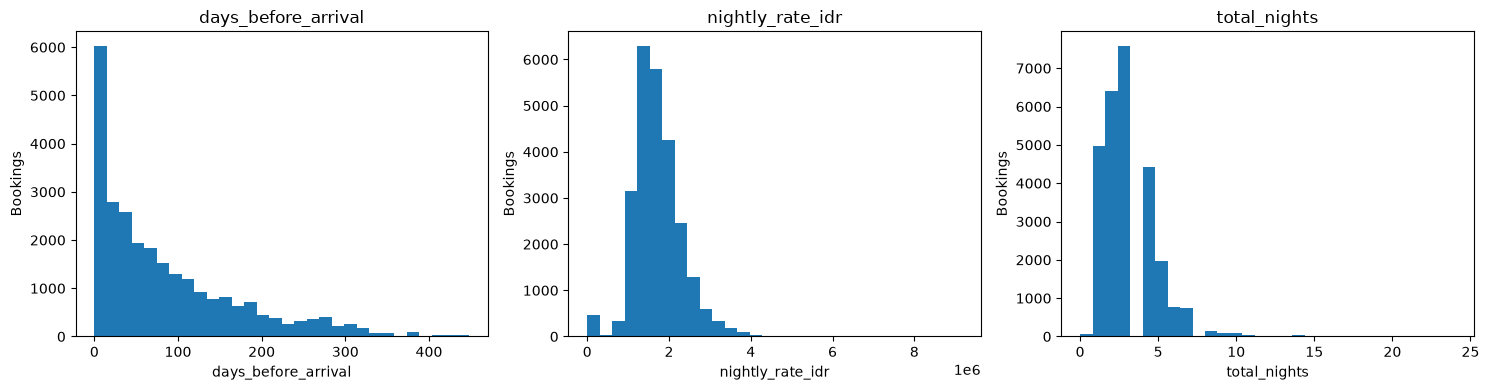

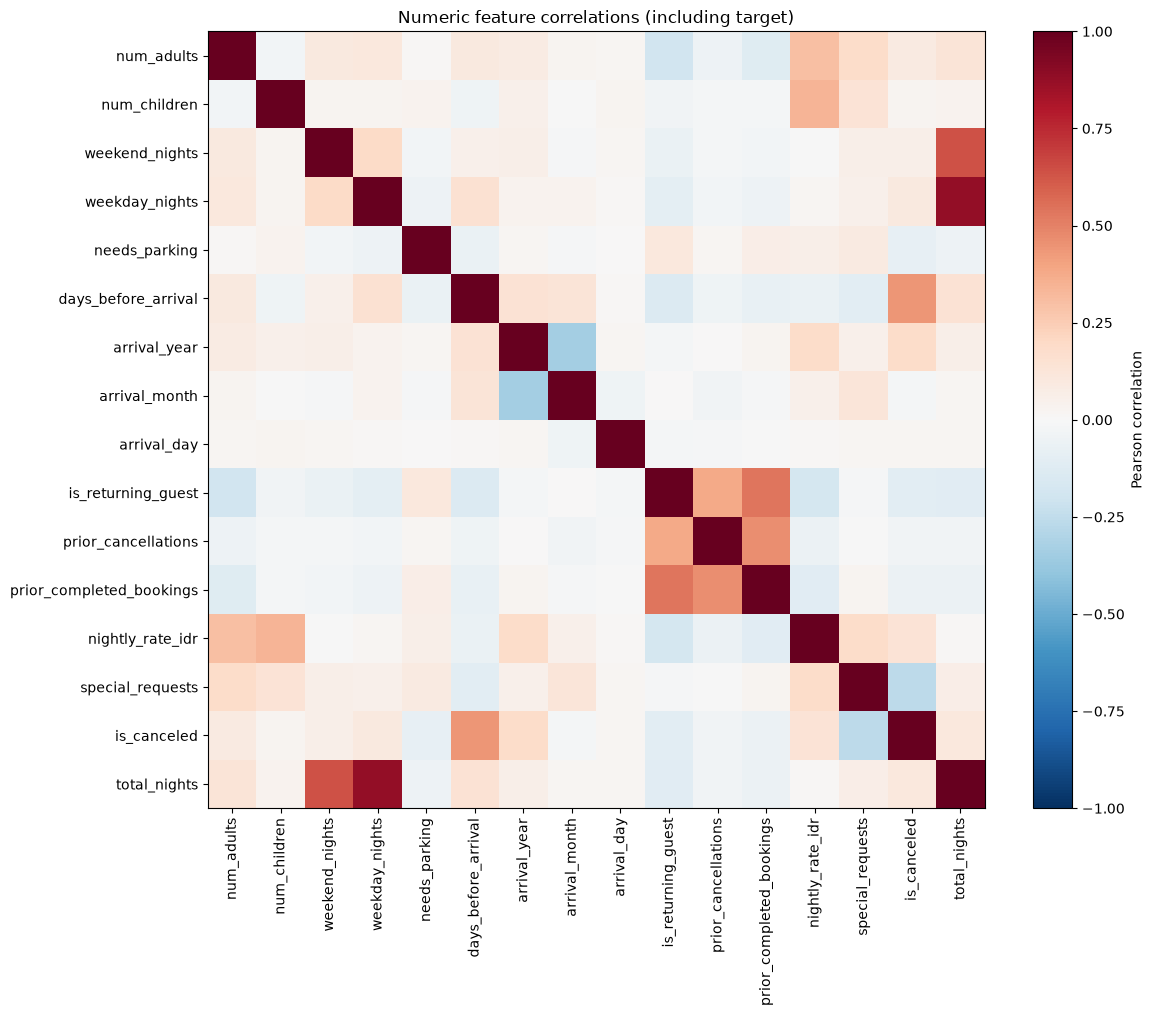

In [26]:
# Distribusi Target
display(train_df[CFG.TARGET].value_counts().sort_index().to_frame("count").assign(
    share=lambda counts: counts["count"] / counts["count"].sum(),
))


# Distribusi Fitur Numerik
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["days_before_arrival", "nightly_rate_idr", "total_nights"]):
    if column == "total_nights":
        (train_df["weekday_nights"] + train_df["weekend_nights"]).plot.hist(bins=30, ax=ax)
    else:
        train_df[column].plot.hist(bins=30, ax=ax)
    ax.set(title=column, xlabel=column, ylabel="Bookings")
fig.tight_layout()
plt.show()

# Korelasi Pearson antarfitur Numerik
plt.figure(figsize=(12, 10))
plt.imshow(train_df.assign(
    total_nights=train_df["weekday_nights"] + train_df["weekend_nights"],
).drop(columns=CFG.ID).corr(numeric_only=True), vmin=-1, vmax=1, cmap="RdBu_r")
plt.xticks(
    range(len(train_df.select_dtypes(include="number").columns) + 1),
    [*train_df.select_dtypes(include="number").columns, "total_nights"], rotation=90,
)
plt.yticks(
    range(len(train_df.select_dtypes(include="number").columns) + 1),
    [*train_df.select_dtypes(include="number").columns, "total_nights"],
)
plt.title("Numeric feature correlations (including target)")
plt.colorbar(label="Pearson correlation")
plt.tight_layout()
plt.show()

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [27]:
# Missing values
display(pd.concat({
    "train": pd.DataFrame({"count": train_df.isna().sum(), "percent": train_df.isna().mean().mul(100)}),
    "test": pd.DataFrame({"count": test_df.isna().sum(), "percent": test_df.isna().mean().mul(100)}),
}, axis=1).round(2))

# Duplikasi
display(pd.DataFrame({
    name: {
        f"{CFG.ID} kosong": frame[CFG.ID].isna().sum(),
        f"{CFG.ID} duplikat (tanpa missing)": frame[CFG.ID].dropna().duplicated().sum(),
        "Baris duplikat lengkap": frame.duplicated().sum(),
        "Prediktor berulang": frame.duplicated(subset=test_df.columns.drop(CFG.ID)).sum(),
    }
    for name, frame in (("train", train_df), ("test", test_df))
}))

# Nilai nol
for name, frame in (("train", train_df), ("test", test_df)):
    print(name)
    display(pd.Series({
        "num_adults = 0": frame["num_adults"].eq(0).sum(),
        "weekday_nights + weekend_nights = 0": (frame["weekday_nights"] + frame["weekend_nights"]).eq(0).sum(),
        "nightly_rate_idr = 0": frame["nightly_rate_idr"].eq(0).sum(),
        "arrival_year/month/day tidak valid atau kosong": pd.to_datetime({
            "year": frame["arrival_year"],
            "month": frame["arrival_month"],
            "day": frame["arrival_day"],
        }, errors="coerce").isna().sum(),
    }))
    display(pd.Series({
        column: (frame[column].notna() & ~frame[column].isin([0, 1])).sum()
        for column in ("needs_parking", "is_returning_guest")
    }, name="Nilai selain 0/1 (tanpa missing)"))


train           test        
                         count percent  count percent
id                           0    0.00    0.0    0.00
num_adults                 809    2.96  180.0    2.63
num_children              3035   11.09  747.0   10.91
weekend_nights               0    0.00    0.0    0.00
weekday_nights               0    0.00    0.0    0.00
meal_package              1760    6.43  442.0    6.46
needs_parking             1082    3.95  247.0    3.61
room_category             1002    3.66  242.0    3.54
days_before_arrival       1123    4.10  290.0    4.24
arrival_year                 0    0.00    0.0    0.00
arrival_month                0    0.00    0.0    0.00
arrival_day                  0    0.00    0.0    0.00
booking_channel              0    0.00    0.0    0.00
is_returning_guest           0    0.00    0.0    0.00
prior_cancellations          0    0.00    0.0    0.00
prior_completed_bookings     0    0.00    0.0    0.00
nightly_rate_idr          2038    7.45  540.0    7.89
special_requests          2500    9.13  593.0    8.66
is_canceled                  0    0.00    NaN     NaN

,train,test
id kosong,0,0
id duplikat (tanpa missing),0,0
Baris duplikat lengkap,0,0
Prediktor berulang,66,3


train


num_adults = 0                                    106
weekday_nights + weekend_nights = 0                64
nightly_rate_idr = 0                              413
arrival_year/month/day tidak valid atau kosong      0
dtype: int64

needs_parking         0
is_returning_guest    0
Name: Nilai selain 0/1 (tanpa missing), dtype: int64

test


num_adults = 0                                    22
weekday_nights + weekend_nights = 0                9
nightly_rate_idr = 0                              85
arrival_year/month/day tidak valid atau kosong     0
dtype: int64

needs_parking         0
is_returning_guest    0
Name: Nilai selain 0/1 (tanpa missing), dtype: int64

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [28]:
train_set, val_set = train_test_split(
    train_df,
    test_size = 0.2,
    stratify = train_df[CFG.TARGET],
    random_state = CFG.SEED
)

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [29]:
X_train = train_set.drop(columns=[CFG.ID, CFG.TARGET]).copy()
X_val = val_set.drop(columns=[CFG.ID, CFG.TARGET]).copy()
y_train = train_set[CFG.TARGET].copy()
y_val = val_set[CFG.TARGET].copy()

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [30]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.columns.difference(numeric_columns, sort=False).tolist()

missing_imputer = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True), numeric_columns),
    ("categorical", SimpleImputer(strategy="constant", fill_value="<missing>", keep_empty_features=True), categorical_columns),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train = missing_imputer.fit_transform(X_train)
X_val = missing_imputer.transform(X_val)

### Duplicates

This part covers repeated records.

In [ ]:
# [Tidak handle duplicate]
display(pd.Series({
    "train_duplicate_rows": train_set.duplicated().sum(),
    "validation_duplicate_rows": val_set.duplicated().sum(),
    "train_repeated_predictors": train_set.drop(columns=[CFG.ID, CFG.TARGET]).duplicated().sum(),
}, name="count"))

train_duplicate_rows          0
validation_duplicate_rows     0
train_repeated_predictors    41
Name: count, dtype: int64

### Outliers

This part covers values far from the rest of the data.

In [ ]:
# [Tidak handle outlier]
display(X_train[numeric_columns].describe(percentiles=[0.01, 0.5, 0.99]).T[
    ["min", "1%", "50%", "99%", "max"]
])

,min,1%,50%,99%,max
num_adults,0.0,1.0,2.0,3.00,4.0
num_children,0.0,0.0,0.0,2.00,10.0
weekend_nights,0.0,0.0,1.0,2.00,7.0
weekday_nights,0.0,0.0,2.0,6.00,17.0
needs_parking,0.0,0.0,0.0,1.00,1.0
days_before_arrival,0.0,0.0,57.0,342.03,448.0
arrival_year,2023.0,2023.0,2024.0,2024.00,2024.0
arrival_month,1.0,1.0,8.0,12.00,12.0
arrival_day,1.0,1.0,16.0,31.00,31.0
is_returning_guest,0.0,0.0,0.0,1.00,1.0


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [30]:
# Write your code here

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

In [33]:
def construct_features(frame):
    return frame.assign(total_nights=frame["weekday_nights"] + frame["weekend_nights"])

X_train = construct_features(X_train)
X_val = construct_features(X_val)
numeric_columns = numeric_columns + ["total_nights"]

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [34]:
def scale_features(frame, means, scales):
    frame = frame.copy()
    frame[means.index] = (frame[means.index] - means) / scales
    return frame

numeric_means = X_train[numeric_columns].mean()
numeric_scales = X_train[numeric_columns].std(ddof=0).replace(0, 1.0)

X_train = scale_features(X_train, numeric_means, numeric_scales)
X_val = scale_features(X_val, numeric_means, numeric_scales)

### Encoding

This part covers the numeric representation of categorical attributes.

In [35]:
def encode_features(frame, levels):
    frame = frame.assign(**{
        column: pd.Categorical(frame[column], categories=categories)
        for column, categories in levels.items()
    })
    return pd.get_dummies(frame, columns=list(levels), dtype=float)

category_levels = {
    column: sorted(set(X_train[column]) | {"<missing>"})
    for column in categorical_columns
}
X_train = encode_features(X_train, category_levels)
X_val = encode_features(X_val, category_levels)

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [34]:
# Write your code here


## Class Balance

This part covers the proportion of each class in the training data.

In [36]:
display(pd.DataFrame({
    "count": y_train.value_counts(),
    "share": y_train.value_counts(normalize=True),
}).sort_index())


,count,share
is_canceled,,
0,14723,0.672345
1,7175,0.327655


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [37]:
X_train = X_train.astype(float)
X_val = X_val.astype(float)
y_train = y_train.astype(int)
y_val = y_val.astype(int)
print(f"Training: {X_train.shape}\nvalidation: {X_val.shape}")

Training: (21898, 40)
validation: (5475, 40)


---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

In [38]:
def fit_preparation(raw):
    imputer = clone(missing_imputer).fit(raw)
    frame = construct_features(imputer.transform(raw))
    numeric_columns = raw.select_dtypes(include="number").columns.tolist() + ["total_nights"]
    categorical = raw.select_dtypes(exclude="number").columns
    return {
        "features": raw.columns.tolist(),
        "imputer": imputer,
        "means": frame[numeric_columns].mean(),
        "scales": frame[numeric_columns].std(ddof=0).replace(0, 1.0),
        "categories": {
            column: sorted(set(frame[column]) | {"<missing>"})
            for column in categorical
        },
    }

def prepare(raw, state):
    frame = state["imputer"].transform(raw[state["features"]])
    frame = construct_features(frame)
    frame = scale_features(frame, state["means"], state["scales"])
    return encode_features(frame, state["categories"]).astype(float)

X_train_raw = train_set.drop(columns=[CFG.ID, CFG.TARGET])
X_val_raw = val_set.drop(columns=[CFG.ID, CFG.TARGET])
X_test_raw = test_df.drop(columns=CFG.ID)

preparation = fit_preparation(X_train_raw)
X_train = prepare(X_train_raw, preparation)
X_val = prepare(X_val_raw, preparation)
X_test = prepare(X_test_raw, preparation)
print(f"Prepared matrices: train {X_train.shape}, validation {X_val.shape}, test {X_test.shape}")

Prepared matrices: train (21898, 40), validation (5475, 40), test (6844, 40)


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

In [41]:
fitted_models = {}
valid_predictions = {}

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [ ]:
# Parameter
knn_params = dict(n_neighbors=5)

# Training and Validation 
model = KNN(**knn_params).fit(X_train, y_train)

predictions = model.predict(X_val)
fitted_models["KNN"] = model
valid_predictions["KNN"] = predictions

print(f"KNN: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

KNN: validation accuracy = 0.8289


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [ ]:
# Parameter
tree_params = dict(max_depth=10, min_samples_leaf=20, random_state=CFG.SEED)

for name, model_class in (
    ("Decision Tree", DecisionTree),
    ("Optimized Decision Tree", OptimizedTree),
):
    model = model_class(**tree_params).fit(X_train, y_train)
    predictions = model.predict(X_val)

    fitted_models[name] = model
    valid_predictions[name] = predictions
    
    print(f"{name}: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Decision Tree: validation accuracy = 0.8504
Optimized Decision Tree: validation accuracy = 0.8473


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [44]:

# Parameter Model
lr_candidates = {
    "Logistic regression (L2)": (LogisticRegression, dict(
        penalty="l2", alpha=0.001, batch_size=256, max_iter=100, random_state=CFG.SEED,
    )),
}
for penalty in ("l1", "l2", "elasticnet"):
    lr_candidates[f"Optimized logistic regression ({penalty})"] = (LROptimized, dict(
        penalty=penalty, alpha=0.001, max_iter=100, random_state=CFG.SEED,
    ))

# Training and Validation
for name, (model_class, params) in lr_candidates.items():
    model = model_class(**params).fit(X_train, y_train)

    predictions = model.predict(X_val)
    fitted_models[name] = model
    valid_predictions[name] = predictions
    
    print(f"{name}: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Logistic regression (L2): validation accuracy = 0.7976
Optimized logistic regression (l1): validation accuracy = 0.7907
Optimized logistic regression (l2): validation accuracy = 0.7963
Optimized logistic regression (elasticnet): validation accuracy = 0.7923


## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [46]:
# Limit Baris (Prevent Kebutuhan Memory yang besar)
SVM_TRAIN_LIMIT = 3000
svm_rng = np.random.default_rng(CFG.SEED)
svm_labels = y_train.to_numpy()
svm_limit = min(SVM_TRAIN_LIMIT, len(svm_labels))

kept = np.flatnonzero(svm_labels == 0)
canceled = np.flatnonzero(svm_labels == 1)
n_canceled = round(svm_limit * len(canceled) / len(svm_labels))

# Convert Data
svm_indices = np.concatenate([
    svm_rng.choice(kept, svm_limit - n_canceled, replace=False),
    svm_rng.choice(canceled, n_canceled, replace=False),
])
X_svm = X_train.to_numpy()[svm_indices]
y_svm = 2 * svm_labels[svm_indices] - 1
X_val_svm = X_val.to_numpy()
gamma = 1.0 / X_train.shape[1]

# Parameter 
svm_params = {
    "SVM (linear)": dict(kernel="linear", c=1.0),
    "SVM (polynomial)": dict(kernel="polynomial", c=1.0, gamma=gamma, r=1.0, p=2),
    "SVM (gaussian)": dict(kernel="gaussian", c=1.0, gamma=gamma),
}

# Training and Validation
for name, params in svm_params.items():
    print(f"Training {name}, shape={X_svm.shape}", flush=True)
    model = SVM(**params).fit(X_svm, y_svm)

    predictions = np.array([(model.predict(row) + 1) // 2 for row in X_val_svm], dtype=int)
    fitted_models[name] = model
    valid_predictions[name] = predictions

    print(f"{name}: {svm_limit:,} training rows, validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Training SVM (linear), shape=(3000, 40)


/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/qpsolvers/conversions/ensure_sparse_matrices.py:28: SparseConversionWarning: Converted matrix 'P' of your problem to scipy.sparse.csc_matrix to pass it to solver 'osqp'; for best performance, build your matrix as a csc_matrix directly.
  warnings.warn(
/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/qpsolvers/conversions/ensure_sparse_matrices.py:28: SparseConversionWarning: Converted matrix 'A' of your problem to scipy.sparse.csc_matrix to pass it to solver 'osqp'; for best performance, build your matrix as a csc_matrix directly.
  warnings.warn(


-----------------------------------------------------------------
           OSQP v1.0.0  -  Operator Splitting QP Solver
              (c) The OSQP Developer Team
-----------------------------------------------------------------
problem:  variables n = 3000, constraints m = 3001
          nnz(P) + nnz(A) = 4507500
settings: algebra = Built-in,
          OSQPInt = 4 bytes, OSQPFloat = 8 bytes,
          linear system solver = QDLDL v0.1.8,
          eps_abs = 1.0e-06, eps_rel = 1.0e-06,
          eps_prim_inf = 1.0e-04, eps_dual_inf = 1.0e-04,
          rho = 1.00e-01 (adaptive: 50 iterations),
          sigma = 1.00e-06, alpha = 1.60, max_iter = 10000000
          check_termination: on (interval 25, duality gap: on),
          time_limit: 1.00e+10 sec,
          scaling: on (10 iterations), scaled_termination: off
          warm starting: on, polishing: off, 
iter   objective    prim res   dual res   gap        rel kkt    rho         time
   1  -2.4347e+03   4.21e+00   2.67e+00  -1.75

SVM Tanpa Limit baris (Komputasi lebih berat)

In [ ]:
# Seluruh baris
X_svm_full = X_train.to_numpy()
y_svm_full = 2 * y_train.to_numpy() - 1

for name, params in svm_params.items():
    name = name.replace("SVM (", "SVM no limit (", 1)
    model = SVM(**params).fit(X_svm_full, y_svm_full)
    predictions = np.array([
        (model.predict(row) + 1) // 2 for row in X_val.to_numpy()
    ], dtype=int)
    fitted_models[name] = model
    valid_predictions[name] = predictions
    print(f"{name}: {len(y_svm_full):,} training rows, validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [45]:
# Parameter Model
nb_params = dict(mode="mixed", alpha=1.0, var_smoothing=1e-9)

# Training and Validation
model = NaiveBayes(**nb_params).fit(X_train, y_train)

predictions = model.predict(X_val)
fitted_models["Naive Bayes"] = model
valid_predictions["Naive Bayes"] = predictions

print(f"Naive Bayes: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Naive Bayes: validation accuracy = 0.5538


## Model Evaluation

This part compares the validation results of all models.

In [ ]:
# Baseline 
actual_y = y_val.to_numpy()
evaluation_predictions = {
    **valid_predictions,
}
evaluation_models = {
    **fitted_models,
}

# Metrik Kelas dan Confusion Matrix
results = []
for name, predicted in evaluation_predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_y, predicted, average="binary", pos_label=1, zero_division=0,
    )

    tn, fp, fn, tp = confusion_matrix(actual_y, predicted, labels=[0, 1]).ravel()

    results.append({
        "model": name,
        "train_rows": (len(evaluation_models[name].kernel_value)
                       if name in evaluation_models and hasattr(evaluation_models[name], "kernel_value")
                       else len(y_train)),
        "accuracy": accuracy_score(actual_y, predicted),
        "precision": precision, "recall": recall, "f1": f1,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

    print(name)
    display(pd.DataFrame(
        [[tn, fp], [fn, tp]],
        index=pd.Index([0, 1], name="Actual"),
        columns=pd.Index([0, 1], name="Predicted"),
    ))

# Sorted by F1
scores = pd.DataFrame(results).set_index("model").sort_values(
    ["f1", "accuracy"], ascending=False, kind="stable",
)
display(scores.round(4))
winner = scores.index[0]
print(f"Selected model: {winner}")

KNN


Predicted,0,1
Actual,,
0,3269,412
1,525,1269


Decision Tree


Predicted,0,1
Actual,,
0,3397,284
1,535,1259


Optimized Decision Tree


Predicted,0,1
Actual,,
0,3398,283
1,553,1241


... (14 outputs left out)

SVM (gaussian)


Predicted,0,1
Actual,,
0,3390,291
1,775,1019


,train_rows,accuracy,precision,recall,f1,TN,FP,FN,TP
model,,,,,,,,,
Decision Tree,21898,0.8504,0.8159,0.7018,0.7546,3397,284,535,1259
Optimized Decision Tree,21898,0.8473,0.8143,0.6918,0.7480,3398,283,553,1241
KNN,21898,0.8289,0.7549,0.7074,0.7304,3269,412,525,1269
Optimized logistic regression (l2),21898,0.7963,0.7161,0.6271,0.6686,3235,446,669,1125
Logistic regression (L2),21898,0.7976,0.7272,0.6120,0.6646,3269,412,696,1098
SVM (linear),3000,0.7978,0.7307,0.6065,0.6628,3280,401,706,1088
SVM (polynomial),3000,0.8042,0.7690,0.5753,0.6582,3371,310,762,1032
SVM (gaussian),3000,0.8053,0.7779,0.5680,0.6566,3390,291,775,1019
Optimized logistic regression (elasticnet),21898,0.7923,0.7197,0.5998,0.6543,3262,419,718,1076


Selected model: Decision Tree


## Improvements 

Bagian ini mencakup:
1. Hyperparameter Tuning
2. 5-Fold dengan Cross-Validation

In [ ]:
# 1. Konfigurasi dan fungsi tuning
# Parameter
tuning_selection = {
    "KNN": "KNN",
    "Tree": "Optimized Decision Tree",
    "LR": "Optimized logistic regression (l2)",
    "SVM": "SVM (gaussian)",
    "NB": "Naive Bayes",
}
tuning_grid = {
    "KNN": {"n_neighbors": [3, 5, 9]},
    "Tree": {"max_depth": [6, 10, 14], "min_samples_leaf": [10, 20]},
    "LR": {"alpha": [0.0001, 0.001, 0.01]},
    "SVM": {"c": [0.1, 1.0, 10.0]},
    "NB": {"alpha": [0.1, 1.0, 10.0]},
}
tuning_svm_limit = 3000  
tuning_families = {
    KNN: "KNN", DecisionTree: "Tree", OptimizedTree: "Tree",
    LogisticRegression: "LR", LROptimized: "LR", SVM: "SVM", NaiveBayes: "NB",
}
tuning_winner = scores.index[0]
tuning_results = {}

# Setiap fold memakai preprocessing yang dipelajari dari bagian train fold itu saja.
tuning_folds = []
for train_idx, check_idx in StratifiedKFold(
    n_splits=5, shuffle=True, random_state=CFG.SEED,
).split(X_train_raw, y_train):
    raw = X_train_raw.iloc[train_idx]
    state = fit_preparation(raw)
    tuning_folds.append((
        prepare(raw, state), y_train.iloc[train_idx],
        prepare(X_train_raw.iloc[check_idx], state), y_train.iloc[check_idx],
    ))


def tuning_fit_predict(name, params, X_fit, y_fit, X_check):
    model = type(evaluation_models[name])(**params)
    if isinstance(model, SVM):
        labels = y_fit.to_numpy()
        indices = np.arange(len(labels))
        if "no limit" not in name:
            limit = min(tuning_svm_limit, len(labels))
            kept, canceled = np.flatnonzero(labels == 0), np.flatnonzero(labels == 1)
            n_canceled = round(limit * len(canceled) / len(labels))
            rng = np.random.default_rng(CFG.SEED)
            indices = np.concatenate([
                rng.choice(kept, limit - n_canceled, replace=False),
                rng.choice(canceled, n_canceled, replace=False),
            ])
        model.fit(X_fit.to_numpy()[indices], 2 * labels[indices] - 1)
        predictions = [(model.predict(row) + 1) // 2 for row in X_check.to_numpy()]
    else:
        model.fit(X_fit, y_fit)
        predictions = model.predict(X_check)
    return model, np.asarray(predictions)


def tune_model(name):
    original = evaluation_models[name]
    family = tuning_families[type(original)]
    grid = tuning_grid[family]
    base = {key: getattr(original, key) for key in signature(type(original)).parameters}
    initial = {key: base[key] for key in grid}
    candidates = [initial] + [p for p in ParameterGrid(grid) if p != initial]
    rows = []
    for candidate in candidates:
        fold_scores = []
        try:
            for X_fit, y_fit, X_check, y_check in tuning_folds:
                _, pred = tuning_fit_predict(name, base | candidate, X_fit, y_fit, X_check)
                fold_scores.append(f1_score(y_check, pred, zero_division=0))
        except (ValueError, RuntimeError) as error:
            print(f"{name} {candidate}: {error}")
            continue
        rows.append({"params": candidate, "mean_f1": np.mean(fold_scores),
                     "std_f1": np.std(fold_scores), "baseline": candidate == initial})
    if not rows:
        raise ValueError(f"Semua kandidat gagal untuk {name}")

    ranking = pd.DataFrame(rows).sort_values("mean_f1", ascending=False, kind="stable")
    print(name)
    display(ranking.reset_index(drop=True))
    best = ranking.iloc[0]
    model, pred = tuning_fit_predict(name, base | best["params"], X_train, y_train, X_val)
    return {"model": model, "predictions": pred, "params": best["params"],
            "mean_f1": best["mean_f1"], "std_f1": best["std_f1"]}


def tuning_metrics(predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, predictions, average="binary", zero_division=0,
    )
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_val, predictions), "precision": precision,
            "recall": recall, "f1": f1, "TN": tn, "FP": fp, "FN": fn, "TP": tp}


In [58]:
# 2. Tuning Model Terbaik dari Evaluation
tuning_results[tuning_winner] = tune_model(tuning_winner)

Decision Tree


,params,mean_f1,std_f1,baseline
0,"{'max_depth': 10, 'min_samples_leaf': 10}",0.750177,0.011995,False
1,"{'max_depth': 10, 'min_samples_leaf': 20}",0.744933,0.007853,True
2,"{'max_depth': 14, 'min_samples_leaf': 10}",0.741363,0.013570,False
3,"{'max_depth': 14, 'min_samples_leaf': 20}",0.735690,0.009175,False
4,"{'max_depth': 6, 'min_samples_leaf': 10}",0.716792,0.006647,False
5,"{'max_depth': 6, 'min_samples_leaf': 20}",0.715860,0.007710,False


In [59]:
# 3. Satu varian pilihan untuk tiap keluarga model lainnya
tuning_results = {tuning_winner: tuning_results[tuning_winner]}
winner_family = tuning_families[type(evaluation_models[tuning_winner])]
for family, name in tuning_selection.items():
    if family == winner_family:
        continue
    if name not in evaluation_models or tuning_families[type(evaluation_models[name])] != family:
        raise ValueError(f"Pilih model dari keluarga {family} yang sudah dievaluasi: {name}")
    tuning_results[name] = tune_model(name)


KNN


,params,mean_f1,std_f1,baseline
0,{'n_neighbors': 9},0.721840,0.011349,False
1,{'n_neighbors': 5},0.718962,0.010373,True
2,{'n_neighbors': 3},0.709812,0.009792,False


Optimized logistic regression (l2)


,params,mean_f1,std_f1,baseline
0,{'alpha': 0.0001},0.664391,0.012060,False
1,{'alpha': 0.001},0.661659,0.009714,True
2,{'alpha': 0.01},0.653832,0.014376,False


/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/qpsolvers/conversions/ensure_sparse_matrices.py:28: SparseConversionWarning: Converted matrix 'P' of your problem to scipy.sparse.csc_matrix to pass it to solver 'osqp'; for best performance, build your matrix as a csc_matrix directly.
  warnings.warn(
/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/qpsolvers/conversions/ensure_sparse_matrices.py:28: SparseConversionWarning: Converted matrix 'A' of your problem to scipy.sparse.csc_matrix to pass it to solver 'osqp'; for best performance, build your matrix as a csc_matrix directly.
  warnings.warn(


-----------------------------------------------------------------
           OSQP v1.0.0  -  Operator Splitting QP Solver
              (c) The OSQP Developer Team
-----------------------------------------------------------------
problem:  variables n = 3000, constraints m = 3001
          nnz(P) + nnz(A) = 4507500
settings: algebra = Built-in,
          OSQPInt = 4 bytes, OSQPFloat = 8 bytes,
          linear system solver = QDLDL v0.1.8,
          eps_abs = 1.0e-06, eps_rel = 1.0e-06,
          eps_prim_inf = 1.0e-04, eps_dual_inf = 1.0e-04,
          rho = 1.00e-01 (adaptive: 50 iterations),
          sigma = 1.00e-06, alpha = 1.60, max_iter = 10000000
          check_termination: on (interval 25, duality gap: on),
          time_limit: 1.00e+10 sec,
          scaling: on (10 iterations), scaled_termination: off
          warm starting: on, polishing: off, 
iter   objective    prim res   dual res   gap        rel kkt    rho         time
   1  -2.4236e+03   3.59e+00   3.45e+00  -1.74

... (28 outputs left out)

,params,mean_f1,std_f1,baseline
0,{'c': 1.0},0.671474,0.024959,True
1,{'c': 10.0},0.661570,0.024111,False
2,{'c': 0.1},0.655948,0.019127,False


/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/qpsolvers/conversions/ensure_sparse_matrices.py:28: SparseConversionWarning: Converted matrix 'P' of your problem to scipy.sparse.csc_matrix to pass it to solver 'osqp'; for best performance, build your matrix as a csc_matrix directly.
  warnings.warn(
/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/qpsolvers/conversions/ensure_sparse_matrices.py:28: SparseConversionWarning: Converted matrix 'A' of your problem to scipy.sparse.csc_matrix to pass it to solver 'osqp'; for best performance, build your matrix as a csc_matrix directly.
  warnings.warn(


-----------------------------------------------------------------
           OSQP v1.0.0  -  Operator Splitting QP Solver
              (c) The OSQP Developer Team
-----------------------------------------------------------------
problem:  variables n = 3000, constraints m = 3001
          nnz(P) + nnz(A) = 4507500
settings: algebra = Built-in,
          OSQPInt = 4 bytes, OSQPFloat = 8 bytes,
          linear system solver = QDLDL v0.1.8,
          eps_abs = 1.0e-06, eps_rel = 1.0e-06,
          eps_prim_inf = 1.0e-04, eps_dual_inf = 1.0e-04,
          rho = 1.00e-01 (adaptive: 50 iterations),
          sigma = 1.00e-06, alpha = 1.60, max_iter = 10000000
          check_termination: on (interval 25, duality gap: on),
          time_limit: 1.00e+10 sec,
          scaling: on (10 iterations), scaled_termination: off
          warm starting: on, polishing: off, 
iter   objective    prim res   dual res   gap        rel kkt    rho         time
   1  -2.4347e+03   4.21e+00   2.67e+00  -1.75

,params,mean_f1,std_f1,baseline
0,{'alpha': 0.1},0.580590,0.019316,False
1,{'alpha': 1.0},0.579633,0.019174,True
2,{'alpha': 10.0},0.576931,0.020147,False


In [60]:
# 4. Bandingkan pasangan model pada validation set yang sama
tuning_comparison = []
for name, result in tuning_results.items():
    old = tuning_metrics(evaluation_predictions[name])
    new = tuning_metrics(result["predictions"])
    tuning_comparison.append({
        "model": name, "params": result["params"], "cv_mean_f1": result["mean_f1"],
        "cv_std_f1": result["std_f1"], "delta_f1": new["f1"] - old["f1"],
    })
    print(name)
    display(pd.DataFrame([old, new], index=["Awal", "Tuned"]).round(4))

display(pd.DataFrame(tuning_comparison).set_index("model").round(4))


Decision Tree


,accuracy,precision,recall,f1,TN,FP,FN,TP
Awal,0.8504,0.8159,0.7018,0.7546,3397,284,535,1259
Tuned,0.8477,0.8034,0.7085,0.7530,3370,311,523,1271


KNN


,accuracy,precision,recall,f1,TN,FP,FN,TP
Awal,0.8289,0.7549,0.7074,0.7304,3269,412,525,1269
Tuned,0.8314,0.7677,0.6962,0.7302,3303,378,545,1249


Optimized logistic regression (l2)


,accuracy,precision,recall,f1,TN,FP,FN,TP
Awal,0.7963,0.7161,0.6271,0.6686,3235,446,669,1125
Tuned,0.7978,0.7247,0.6176,0.6669,3260,421,686,1108


SVM (linear)


,accuracy,precision,recall,f1,TN,FP,FN,TP
Awal,0.7978,0.7307,0.6065,0.6628,3280,401,706,1088
Tuned,0.7978,0.7307,0.6065,0.6628,3280,401,706,1088


Naive Bayes


,accuracy,precision,recall,f1,TN,FP,FN,TP
Awal,0.5538,0.4211,0.9649,0.5863,1301,2380,63,1731
Tuned,0.5551,0.4218,0.9649,0.5870,1308,2373,63,1731


,params,cv_mean_f1,cv_std_f1,delta_f1
model,,,,
Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 10}",0.7502,0.0120,-0.0016
KNN,{'n_neighbors': 9},0.7218,0.0113,-0.0002
Optimized logistic regression (l2),{'alpha': 0.0001},0.6644,0.0121,-0.0018
SVM (linear),{'c': 1.0},0.6715,0.0250,0.0000
Naive Bayes,{'alpha': 0.1},0.5806,0.0193,0.0007


In [61]:
# 5. Jalankan untuk mengganti model dengan F1 validasi yang naik
for name, result in tuning_results.items():
    if name in fitted_models and name in valid_predictions:
        current_f1 = f1_score(y_val, valid_predictions[name], zero_division=0)
        tuned_f1 = f1_score(y_val, result["predictions"], zero_division=0)
        if tuned_f1 > current_f1:
            fitted_models[name] = result["model"]
            valid_predictions[name] = result["predictions"]
            print(f"{name}: F1 {current_f1:.4f} -> {tuned_f1:.4f}")


Naive Bayes: F1 0.5863 -> 0.5870


---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [ ]:
# Model Pembanding
sklearn_models = {}
sklearn_predictions = {}
comparison_candidates = {}
comparison_results = []

def record_comparison(name, local_predictions, library_predictions, train_rows):
    for implementation, predicted in (("local", local_predictions), ("sklearn", library_predictions)):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_val, predicted, average="binary", pos_label=1, zero_division=0,
        )

        comparison_results.append({
            "model": name, 
            "implementation": implementation, 
            "train_rows": train_rows,
            "accuracy": accuracy_score(y_val, predicted),
            "precision": precision, "recall": recall, "f1": f1,
        })

# KNN
comparison_candidates["KNN"] = (
    KNeighborsClassifier(
        n_neighbors=fitted_models["KNN"].n_neighbors,
        weights="uniform", metric="euclidean", algorithm="brute",
    ), X_train, y_train, valid_predictions["KNN"],
)

# Decision Tree
for name, local_model in fitted_models.items():
    if isinstance(local_model, (DecisionTree, OptimizedTree)):
        comparison_candidates[name] = (
            DecisionTreeClassifier(**{
                parameter: getattr(local_model, parameter)
                for parameter in ("max_depth", "min_samples_split", "min_samples_leaf", "min_impurity_decrease", "ccp_alpha", "max_features", "random_state")
            }), X_train, y_train, valid_predictions[name],
        )

# Logistic Regression
for name in lr_candidates:
    local_model = fitted_models[name]
    comparison_candidates[name] = (
        SklearnLR(
            solver="saga",
            C=1.0 / (len(y_train) * local_model.alpha),
            l1_ratio=(1.0 if local_model.penalty == "l1" else local_model.l1_ratio if local_model.penalty == "elasticnet" else 0.0),
            max_iter=local_model.max_iter, tol=local_model.tol,
            random_state=local_model.random_state, class_weight=local_model.class_weight,
        ), X_train, y_train, valid_predictions[name],
    )

# SVM
for name, local_model in fitted_models.items():
    if isinstance(local_model, SVM):
        comparison_candidates[name] = (
            SVC(
                C=local_model.c,
                kernel={"linear": "linear", "polynomial": "poly", "gaussian": "rbf"}[local_model.kernel],
                gamma=local_model.gamma, degree=local_model.p, coef0=local_model.r,
                tol=1e-6,
            ),
            X_svm if name in svm_params else X_train,
            y_svm if name in svm_params else 2 * y_train.to_numpy() - 1,
            valid_predictions[name],
        )

# Training and Validation
for name, (comparison_model, train_matrix, train_labels, local_predictions) in comparison_candidates.items():
    comparison_model.fit(train_matrix, train_labels)
    predicted = comparison_model.predict(
        X_val if isinstance(train_matrix, pd.DataFrame) else X_val.to_numpy()
    )

    if isinstance(comparison_model, SVC):
        predicted = (predicted + 1) // 2
    
    sklearn_models[name] = comparison_model
    sklearn_predictions[name] = predicted
    record_comparison(name, local_predictions, predicted, len(train_labels))

# Komparasi
comparison_scores = pd.DataFrame(comparison_results).set_index(["model", "implementation"])
display(comparison_scores.round(4))

/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


train_rows  \
model                                      implementation               
KNN                                        local                21898   
                                           sklearn              21898   
Decision Tree                              local                21898   
                                           sklearn              21898   
Optimized Decision Tree                    local                21898   
                                           sklearn              21898   
Logistic regression (L2)                   local                21898   
                                           sklearn              21898   
Optimized logistic regression (l1)         local                21898   
                                           sklearn              21898   
Optimized logistic regression (l2)         local                21898   
                                           sklearn              21898   
Optimized logistic regression (elasticnet) local                21898   
                                           sklearn              21898   
SVM (linear)                               local                 3000   
                                           sklearn               3000   
SVM (polynomial)                           local                 3000   
                                           sklearn               3000   
SVM (gaussian)                             local                 3000   
                                           sklearn               3000   

                                                           accuracy  \
model                                      implementation             
KNN                                        local             0.8289   
                                           sklearn           0.8289   
Decision Tree                              local             0.8504   
                                           sklearn           0.8473   
Optimized Decision Tree                    local             0.8473   
                                           sklearn           0.8473   
Logistic regression (L2)                   local             0.7976   
                                           sklearn           0.7974   
Optimized logistic regression (l1)         local             0.7907   
                                           sklearn           0.7974   
Optimized logistic regression (l2)         local             0.7963   
                                           sklearn           0.7974   
Optimized logistic regression (elasticnet) local             0.7923   
                                           sklearn           0.7985   
SVM (linear)                               local             0.7978   
                                           sklearn           0.7938   
SVM (polynomial)                           local             0.8042   
                                           sklearn           0.8042   
SVM (gaussian)                             local             0.8053   
                                           sklearn           0.8053   

                                                           precision  recall  \
model                                      implementation                      
KNN                                        local              0.7549  0.7074   
                                           sklearn            0.7549  0.7074   
Decision Tree                              local              0.8159  0.7018   
                                           sklearn            0.8143  0.6918   
Optimized Decision Tree                    local              0.8143  0.6918   
                                           sklearn            0.8143  0.6918   
Logistic regression (L2)                   local              0.7272  0.6120   
                                           sklearn            0.7279  0.6098   
Optimized logistic regression (l1)         local              0.7174  0.5959   
         

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [ ]:
# Save all model
model_dir = CFG.OUTPUT_DIR / "models"
model_dir.mkdir(parents=True, exist_ok=True)

for name, model in fitted_models.items():
    model_path = model_dir / f"{name}.pkl"
    with model_path.open("wb") as file:
        pickle.dump(
            {"name": name, "model": model, "preparation": preparation},
            file,
            protocol=pickle.HIGHEST_PROTOCOL,
        )
    print(f"Saved {model_path}")


Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/KNN.pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Decision Tree.pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Optimized Decision Tree.pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Logistic regression (L2).pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Optimized logistic regression (l1).pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Optimized logistic regression (l2).pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Optimized logistic regression (elasticnet).pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Naive Bayes.pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggl

In [ ]:
# Pilih file model
model_path = CFG.OUTPUT_DIR / "models" / "KNN.pkl"
with model_path.open("rb") as file:
    saved = pickle.load(file)

loaded_name = saved["name"]
loaded_model = saved["model"]
loaded_preparation = saved["preparation"]
print(f"Loaded {loaded_name}")


Loaded KNN


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [63]:
# Dataset untuk Training Terakhir
full_raw = train_df.drop(columns=[CFG.ID, CFG.TARGET])
full_y = train_df[CFG.TARGET].to_numpy(dtype=int)
final_preparation = fit_preparation(full_raw)
X_full = prepare(full_raw, final_preparation)
X_test_final = prepare(test_df.drop(columns=CFG.ID), final_preparation)

# Parameter Model
if isinstance(fitted_models[winner], SVM):
    final_params = {
        parameter: getattr(fitted_models[winner], parameter)
        for parameter in ("gamma", "r", "p", "c", "kernel")
    }
elif winner in lr_candidates:
    final_params = lr_candidates[winner][1]
elif winner == "Naive Bayes":
    final_params = nb_params
else:
    final_params = tree_params
final_model = type(fitted_models[winner])(**final_params)

# Training Ulang
if isinstance(final_model, SVM):
    if winner in svm_params:
        rng = np.random.default_rng(CFG.SEED)
        limit = min(SVM_TRAIN_LIMIT, len(full_y))
        canceled = np.flatnonzero(full_y == 1)
        kept = np.flatnonzero(full_y == 0)
        n_canceled = round(limit * len(canceled) / len(full_y))
        indices = np.concatenate([
            rng.choice(kept, limit - n_canceled, replace=False),
            rng.choice(canceled, n_canceled, replace=False),
        ])
    else:
        indices = np.arange(len(full_y))
    final_model.fit(X_full.to_numpy()[indices], 2 * full_y[indices] - 1)
    test_predictions = np.array([
        (final_model.predict(row) + 1) // 2 for row in X_test_final.to_numpy()
    ], dtype=int)
else:
    final_model.fit(X_full, full_y)
    test_predictions = final_model.predict(X_test_final)

# Validasi Terakhir
sample = pd.read_csv(CFG.DATA_DIR / "sample_submission.csv", dtype={CFG.ID: str})
if (not test_df[CFG.ID].is_unique or not sample[CFG.ID].is_unique or set(test_df[CFG.ID]) != set(sample[CFG.ID])):
    raise ValueError("Test IDs and sample_submission IDs must match and be unique.")

prediction_by_id = pd.Series(test_predictions, index=test_df[CFG.ID])
submission = sample[[CFG.ID]].assign(**{CFG.TARGET: sample[CFG.ID].map(prediction_by_id)})
if not submission[CFG.TARGET].isin([0, 1]).all():
    raise ValueError("Submission contains missing or invalid predictions.")

submission[CFG.TARGET] = submission[CFG.TARGET].astype(int)

# Export CSV
submission_path = CFG.OUTPUT_DIR / "submission.csv"
submission.to_csv(submission_path, index=False)
print(f"Selected model: {winner}")
print(f"Wrote {len(submission):,} predictions to {submission_path}")
display(submission.head())

Selected model: Decision Tree
Wrote 6,844 predictions to /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/submission.csv


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.